# GROUP 14: SURVEY COORDINATE DISTANCE CALCULATOR

## Program Description

The Survey Coordinate Distance Calculator is a Python-based program developed to process survey coordinate data stored in CSV (Comma-Separated Values) files.

The program reads survey point coordinates in PNEZD format, calculates distances between consecutive survey points, displays the computed results and exports the results into a new CSV file.

The program calculates horizontal distances, slope distances and cumulative horizontal distances using the coordinate differences between successive survey points.

## Input Data Requirements

The input CSV file should contain five columns in the following order:

1. Point Number (P)
2. Northing (N)
3. Easting (E)
4. Elevation (Z)
5. Description (D)

Coordinates should be numerical, and all coordinate values should use consistent units.

## Calculation Methodology

The program uses the following mathematical relationships:

**1. Coordinate differences**

- Change in Easting: ΔE = E₂ − E₁
- Change in Northing: ΔN = N₂ − N₁
- Change in Elevation: ΔZ = Z₂ − Z₁

**2. Horizontal Distance**

HD = √[(ΔE)² + (ΔN)²]

**3. Slope Distance**

SD = √[(ΔE)² + (ΔN)² + (ΔZ)²]

**4. Cumulative Horizontal Distance**

CD = Sum of all horizontal distances between consecutive points.

## Output

The program generates a new CSV file containing the calculated distances between consecutive survey points, together with the corresponding point numbers and cumulative horizontal distances.

In [17]:
# Import required libraries

import pandas as pd # Handles CSV files and tabular data
import numpy as np   # Performs numerical calculations
import ipywidgets as widgets # Provides file upload controls

from google.colab import files
from IPython.display import display, clear_output

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("ipywidgets imported successfully!")

All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
ipywidgets imported successfully!


In [18]:
# Cell 2: Create CSV file upload interface

upload_button = widgets.FileUpload(
    accept='.csv',
    multiple=False,
    description='Choose CSV File'
)

display(upload_button)

FileUpload(value={}, accept='.csv', description='Choose CSV File')

In [19]:
# Cell 3: Upload verification

if upload_button.value:
    uploaded_file = list(upload_button.value.values())[0]

    file_name = uploaded_file['metadata']['name']
    file_content = uploaded_file['content']

    print("File uploaded successfully!")
    print("Filename:", file_name)
    print("File size:", len(file_content), "bytes")

else:
    print("No file uploaded yet. Please select a CSV file.")

File uploaded successfully!
Filename: ASIMO VIVIAN onyakai city west.csv
File size: 448 bytes


In [21]:
# Cell 4: Read and preview CSV data

import io

# Read uploaded CSV file
df = pd.read_csv(
    io.BytesIO(bytes(file_content)),
    header=None,
    sep=None,
    engine='python'
)

# Display information about the dataset
print("CSV file read successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nPreview of survey data:")

display(df.head(10))

CSV file read successfully!
Number of rows: 12
Number of columns: 5

Preview of survey data:


,0,1,2,3,4
0,1,200545.325,567114.632,1089.076,p1
1,2,200559.242,567118.320,1088.464,p2
2,3,200571.631,567074.179,1088.601,p3
3,4,200643.155,567082.513,1086.694,p4
4,5,200635.899,567135.236,1086.008,p5
5,6,200701.127,567149.059,1080.507,p6
6,7,200706.467,567130.897,1083.727,p7
7,8,200725.916,567136.544,1083.026,p8
8,9,200681.092,567250.281,1082.536,p9
9,10,200663.697,567239.698,1083.415,p10


In [22]:
# Cell 5: Assign column names

df.columns = [
    'Point',
    'Northing',
    'Easting',
    'Elevation',
    'Description'
]

# Display the complete dataset
print("Survey data with assigned column names:")

display(df)

Survey data with assigned column names:


,Point,Northing,Easting,Elevation,Description
0,1,200545.325,567114.632,1089.076,p1
1,2,200559.242,567118.320,1088.464,p2
2,3,200571.631,567074.179,1088.601,p3
3,4,200643.155,567082.513,1086.694,p4
4,5,200635.899,567135.236,1086.008,p5
5,6,200701.127,567149.059,1080.507,p6
6,7,200706.467,567130.897,1083.727,p7
7,8,200725.916,567136.544,1083.026,p8
8,9,200681.092,567250.281,1082.536,p9
9,10,200663.697,567239.698,1083.415,p10


In [23]:
# Cell 6: Validate survey coordinates

# Required coordinate columns
coordinate_columns = ['Northing', 'Easting', 'Elevation']

# Convert coordinate columns to numeric values
for column in coordinate_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

# Check for missing or invalid coordinate values
print("SURVEY DATA VALIDATION")
print("-" * 35)

for column in coordinate_columns:
    missing = df[column].isna().sum()
    print(f"{column}: {missing} missing or invalid values")

# Check for duplicate point numbers
duplicates = df['Point'].duplicated().sum()

print("Duplicate point numbers:", duplicates)

# Overall validation
if df[coordinate_columns].isna().any().any() or duplicates > 0:
    print("\nWARNING: Data requires attention.")
else:
    print("\nSUCCESS: All coordinate values are valid!")

SURVEY DATA VALIDATION
-----------------------------------
Northing: 0 missing or invalid values
Easting: 0 missing or invalid values
Elevation: 0 missing or invalid values
Duplicate point numbers: 0

SUCCESS: All coordinate values are valid!


In [24]:
# Cell 7: Calculate coordinate differences

df['Delta_E'] = df['Easting'].diff()
df['Delta_N'] = df['Northing'].diff()
df['Delta_Z'] = df['Elevation'].diff()

print("Coordinate differences calculated successfully!")

display(df[['Point', 'Delta_E', 'Delta_N', 'Delta_Z']])

Coordinate differences calculated successfully!


,Point,Delta_E,Delta_N,Delta_Z
0,1,NaN,NaN,NaN
1,2,3.688,13.917,-0.612
2,3,-44.141,12.389,0.137
3,4,8.334,71.524,-1.907
4,5,52.723,-7.256,-0.686
5,6,13.823,65.228,-5.501
6,7,-18.162,5.340,3.220
7,8,5.647,19.449,-0.701
8,9,113.737,-44.824,-0.490
9,10,-10.583,-17.395,0.879


In [25]:
# Cell 8: Calculate horizontal and slope distances

# Horizontal distance
df['Horizontal_Distance'] = np.sqrt(
    df['Delta_E']**2 + df['Delta_N']**2
)

# Slope distance
df['Slope_Distance'] = np.sqrt(
    df['Delta_E']**2 +
    df['Delta_N']**2 +
    df['Delta_Z']**2
)

print("Horizontal and slope distances calculated successfully!")

Horizontal and slope distances calculated successfully!


In [26]:
# Cell 9: Calculate cumulative horizontal distance

df['Cumulative_Distance'] = (
    df['Horizontal_Distance'].fillna(0).cumsum()
)

print("Cumulative distances calculated successfully!")

Cumulative distances calculated successfully!


In [27]:
# Cell 10: Display calculated survey results

results = df[
    [
        'Point',
        'Northing',
        'Easting',
        'Elevation',
        'Delta_E',
        'Delta_N',
        'Delta_Z',
        'Horizontal_Distance',
        'Slope_Distance',
        'Cumulative_Distance'
    ]
]

print("SURVEY DISTANCE CALCULATION RESULTS")
print("=" * 45)

display(results.round(3))

SURVEY DISTANCE CALCULATION RESULTS


,Point,Northing,Easting,Elevation,Delta_E,Delta_N,Delta_Z,Horizontal_Distance,Slope_Distance,Cumulative_Distance
0,1,200545.325,567114.632,1089.076,NaN,NaN,NaN,NaN,NaN,0.000
1,2,200559.242,567118.320,1088.464,3.688,13.917,-0.612,14.397,14.410,14.397
2,3,200571.631,567074.179,1088.601,-44.141,12.389,0.137,45.847,45.847,60.244
3,4,200643.155,567082.513,1086.694,8.334,71.524,-1.907,72.008,72.033,132.252
4,5,200635.899,567135.236,1086.008,52.723,-7.256,-0.686,53.220,53.224,185.472
5,6,200701.127,567149.059,1080.507,13.823,65.228,-5.501,66.677,66.903,252.148
6,7,200706.467,567130.897,1083.727,-18.162,5.340,3.220,18.931,19.203,271.079
7,8,200725.916,567136.544,1083.026,5.647,19.449,-0.701,20.252,20.264,291.331
8,9,200681.092,567250.281,1082.536,113.737,-44.824,-0.490,122.251,122.252,413.582
9,10,200663.697,567239.698,1083.415,-10.583,-17.395,0.879,20.361,20.380,433.944


In [29]:
# Cell 11: Prepare final output table

output_df = pd.DataFrame({
    'From_Point': df['Point'].shift(1),
    'To_Point': df['Point'],

    'From_Northing': df['Northing'].shift(1),
    'From_Easting': df['Easting'].shift(1),
    'From_Elevation': df['Elevation'].shift(1),

    'To_Northing': df['Northing'],
    'To_Easting': df['Easting'],
    'To_Elevation': df['Elevation'],

    'Delta_E': df['Delta_E'],
    'Delta_N': df['Delta_N'],
    'Delta_Z': df['Delta_Z'],

    'Horizontal_Distance': df['Horizontal_Distance'],
    'Slope_Distance': df['Slope_Distance'],
    'Cumulative_Distance': df['Cumulative_Distance']
})

# Remove the first row (no preceding point)
output_df = output_df.dropna(subset=['From_Point']).reset_index(drop=True)

print("Final output table prepared successfully!")
print("Number of distance records:", len(output_df))

display(output_df.round(3))

Final output table prepared successfully!
Number of distance records: 11


,From_Point,To_Point,From_Northing,From_Easting,From_Elevation,To_Northing,To_Easting,To_Elevation,Delta_E,Delta_N,Delta_Z,Horizontal_Distance,Slope_Distance,Cumulative_Distance
0,1.0,2,200545.325,567114.632,1089.076,200559.242,567118.320,1088.464,3.688,13.917,-0.612,14.397,14.410,14.397
1,2.0,3,200559.242,567118.320,1088.464,200571.631,567074.179,1088.601,-44.141,12.389,0.137,45.847,45.847,60.244
2,3.0,4,200571.631,567074.179,1088.601,200643.155,567082.513,1086.694,8.334,71.524,-1.907,72.008,72.033,132.252
3,4.0,5,200643.155,567082.513,1086.694,200635.899,567135.236,1086.008,52.723,-7.256,-0.686,53.220,53.224,185.472
4,5.0,6,200635.899,567135.236,1086.008,200701.127,567149.059,1080.507,13.823,65.228,-5.501,66.677,66.903,252.148
5,6.0,7,200701.127,567149.059,1080.507,200706.467,567130.897,1083.727,-18.162,5.340,3.220,18.931,19.203,271.079
6,7.0,8,200706.467,567130.897,1083.727,200725.916,567136.544,1083.026,5.647,19.449,-0.701,20.252,20.264,291.331
7,8.0,9,200725.916,567136.544,1083.026,200681.092,567250.281,1082.536,113.737,-44.824,-0.490,122.251,122.252,413.582
8,9.0,10,200681.092,567250.281,1082.536,200663.697,567239.698,1083.415,-10.583,-17.395,0.879,20.361,20.380,433.944
9,10.0,11,200663.697,567239.698,1083.415,200579.980,567227.255,1083.419,-12.443,-83.717,0.004,84.637,84.637,518.580


In [30]:
# Cell 12: Export calculated results to CSV

output_filename = 'Survey_Distance_Results.csv'

output_df.to_csv(
    output_filename,
    index=False,
    float_format='%.3f'
)

print("CSV export completed successfully!")
print("Output filename:", output_filename)

CSV export completed successfully!
Output filename: Survey_Distance_Results.csv


In [31]:
# Cell 13: Download output CSV

download_button = widgets.Button(
    description='Download Results CSV',
    button_style='success',
    icon='download'
)

def download_results(button):
    files.download(output_filename)

download_button.on_click(download_results)

display(download_button)

Button(button_style='success', description='Download Results CSV', icon='download', style=ButtonStyle())

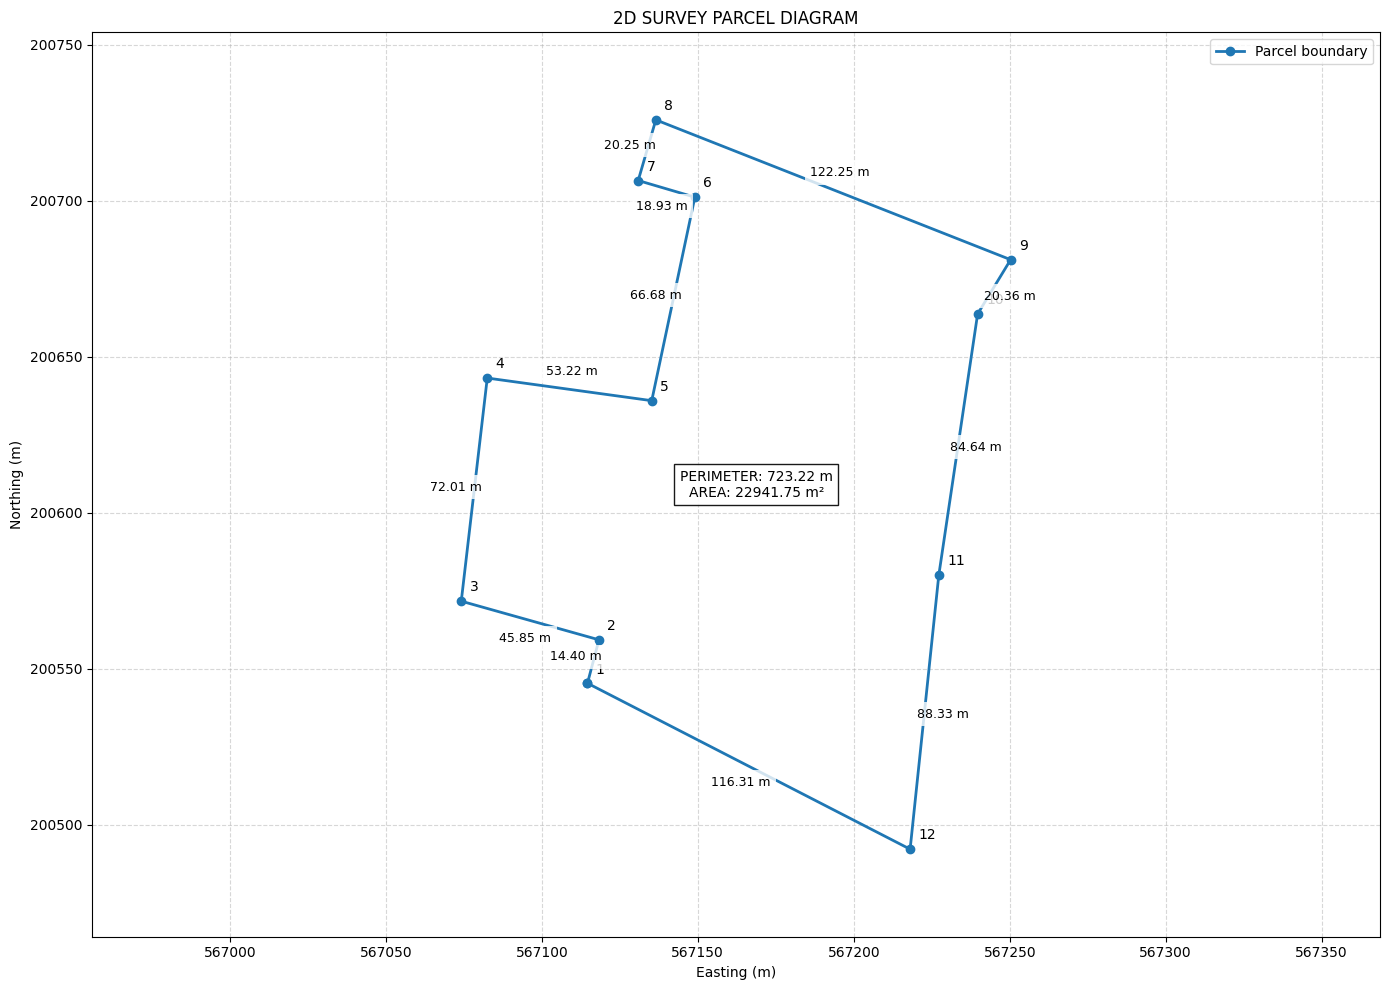

In [33]:
# Import Matplotlib for parcel visualization
import matplotlib.pyplot as plt

# Extract Easting and Northing coordinates
coordinates = df[['Easting', 'Northing']].to_numpy()

# A parcel requires at least three points
if len(coordinates) < 3:
    raise ValueError("At least three points are required to plot a parcel.")

# Close the parcel by connecting the last point to the first
closed_coordinates = np.vstack([coordinates, coordinates[0]])

# Calculate the length of each boundary segment
differences = np.diff(closed_coordinates, axis=0)

segment_lengths = np.sqrt(
    differences[:, 0]**2 + differences[:, 1]**2
)

# Calculate parcel perimeter
perimeter = np.sum(segment_lengths)

# Calculate parcel area using the Shoelace formula
x = closed_coordinates[:, 0]
y = closed_coordinates[:, 1]

cross_products = (
    x[:-1] * y[1:] - x[1:] * y[:-1]
)

area = abs(np.sum(cross_products)) / 2

# Calculate the polygon centroid for the information label
if abs(np.sum(cross_products)) > 1e-10:
    centroid_x = np.sum(
        (x[:-1] + x[1:]) * cross_products
    ) / (3 * np.sum(cross_products))

    centroid_y = np.sum(
        (y[:-1] + y[1:]) * cross_products
    ) / (3 * np.sum(cross_products))
else:
    centroid_x = np.mean(x[:-1])
    centroid_y = np.mean(y[:-1])

# Create the parcel diagram
fig, ax = plt.subplots(figsize=(14, 10))

ax.plot(
    x, y,
    marker='o',
    linestyle='-',
    linewidth=2,
    label='Parcel boundary'
)

# Label each survey point
for i, point in enumerate(df['Point']):
    ax.annotate(
        str(point),
        (coordinates[i, 0], coordinates[i, 1]),
        xytext=(6, 7),
        textcoords='offset points'
    )

# Add distance dimensions along each boundary segment
offset = max(
    np.ptp(coordinates[:, 0]),
    np.ptp(coordinates[:, 1])
) * 0.025

for i, length in enumerate(segment_lengths):

    dx, dy = differences[i]

    midpoint_x = (x[i] + x[i + 1]) / 2
    midpoint_y = (y[i] + y[i + 1]) / 2

    # Offset the dimension label from the boundary line
    if length > 0:
        label_x = midpoint_x - (dy / length) * offset
        label_y = midpoint_y + (dx / length) * offset
    else:
        label_x, label_y = midpoint_x, midpoint_y

    next_index = (i + 1) % len(df)

    ax.text(
        label_x,
        label_y,
        f"{length:.2f} m",
        ha='center',
        va='center',
        fontsize=9,
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
    )

# Display perimeter and area inside the parcel
ax.text(
    centroid_x,
    centroid_y,
    f"PERIMETER: {perimeter:.2f} m\nAREA: {area:.2f} m²",
    ha='center',
    va='center',
    fontsize=10,
    bbox=dict(facecolor='white', alpha=0.9, edgecolor='black')
)

# Add diagram titles and axis labels
ax.set_title("2D SURVEY PARCEL DIAGRAM")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()

# Ensure the entire parcel is visible
ax.margins(0.12)

# Prevent labels and boundary points from being cut off
plt.subplots_adjust(left=0.10, right=0.95, top=0.92, bottom=0.10)
plt.tight_layout()
plt.show()